In [2]:
import os
import pandas as pd

base_dir = r"d:\FakeNewsProject"

languages = {
    "Gujarati": "Gujarati_F&R_News",
    "Hindi":    "Hindi_F&R_News",
    "Marathi":  "Marathi_F&R_News",
    "Telugu":   "Telugu_F&R_News",
}

rows = []
for lang, folder in languages.items():
    for category, label in [("fake_news", 0), ("real_news", 1)]:
        sub = os.path.join(base_dir, folder, f"{lang}_{category}")
        for fname in os.listdir(sub):
            fpath = os.path.join(sub, fname)
            try:
                with open(fpath, "r", encoding="utf-8") as f:
                    text = f.read().strip()
                rows.append({"language": lang, "text": text, "label": label})
            except Exception:
                pass  # skip unreadable files

df = pd.DataFrame(rows)
print(df.shape)
print(df["label"].value_counts())
print(df["language"].value_counts())


(76949, 3)
label
1    39101
0    37848
Name: count, dtype: int64
language
Hindi       20593
Telugu      20001
Marathi     18696
Gujarati    17659
Name: count, dtype: int64


In [3]:
import re

def clean_text(text):
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = re.sub(r"\S+@\S+", "", text)
    text = re.sub(r"[a-zA-Z0-9]", "", text)
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_text)
df = df[df["clean_text"].str.len() > 10].reset_index(drop=True)
print(f"Rows after cleaning: {len(df)}")


Rows after cleaning: 76921


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print(f"Train: {len(X_train)}, Test: {len(X_test)}")


Train: 61536, Test: 15385


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f"TF-IDF matrix shape: {X_train_tfidf.shape}")


TF-IDF matrix shape: (61536, 50000)


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=1.0),
    "Linear SVM":          LinearSVC(max_iter=2000),
    "Naive Bayes":         MultinomialNB(alpha=0.1),
    "Random Forest":       RandomForestClassifier(n_estimators=200, n_jobs=-1),
}

results = {}
for name, model in models.items():
    print(f"\n--- {name} ---")
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=["Fake", "Real"]))



--- Logistic Regression ---
Accuracy: 0.9969
              precision    recall  f1-score   support

        Fake       1.00      0.99      1.00      7564
        Real       0.99      1.00      1.00      7821

    accuracy                           1.00     15385
   macro avg       1.00      1.00      1.00     15385
weighted avg       1.00      1.00      1.00     15385


--- Linear SVM ---
Accuracy: 0.9984
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00      7564
        Real       1.00      1.00      1.00      7821

    accuracy                           1.00     15385
   macro avg       1.00      1.00      1.00     15385
weighted avg       1.00      1.00      1.00     15385


--- Naive Bayes ---
Accuracy: 0.9719
              precision    recall  f1-score   support

        Fake       0.95      1.00      0.97      7564
        Real       1.00      0.95      0.97      7821

    accuracy                           0.97     15385
   macr

In [7]:
import joblib
import os

save_dir = r"d:\FakeNewsProject\Telugu_F&R_News"
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]

joblib.dump(best_model, os.path.join(save_dir, "fake_news_model.pkl"))
joblib.dump(tfidf, os.path.join(save_dir, "tfidf_vectorizer.pkl"))

print(f"Saved best model: {best_model_name}")
print(f"Model classes_: {best_model.classes_}")
print("Label mapping: 0=FAKE, 1=REAL")


Saved best model: Linear SVM
Model classes_: [0 1]
Label mapping: 0=FAKE, 1=REAL


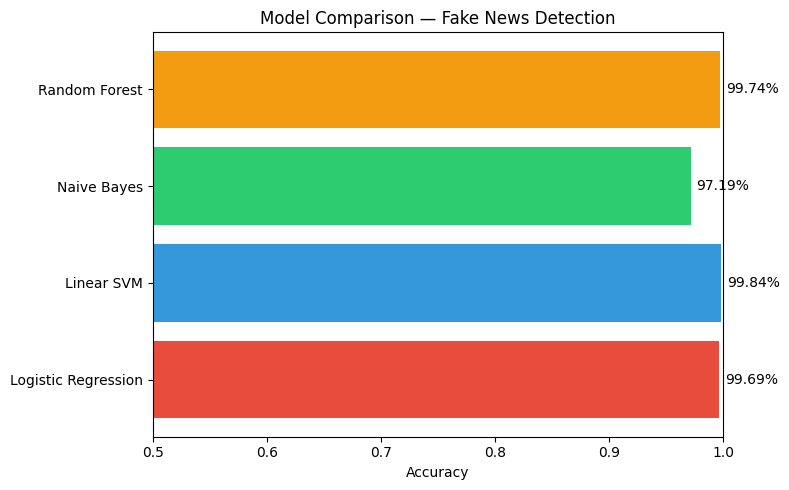

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.barh(list(results.keys()), list(results.values()), color=["#e74c3c","#3498db","#2ecc71","#f39c12"])
plt.xlabel("Accuracy")
plt.title("Model Comparison — Fake News Detection")
plt.xlim(0.5, 1.0)
for i, (name, acc) in enumerate(results.items()):
    plt.text(acc + 0.005, i, f"{acc:.2%}", va="center")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()


In [10]:
# ── PREDICTION CELL ──────────────────────────────────────────────────────────
# This cell is fully self-contained. Run ONLY this cell after any restart.
# No need to re-run training cells.
import joblib, os, re

def clean_text(text):
    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = re.sub(r"\S+@\S+", "", text)
    text = re.sub(r"[a-zA-Z0-9]", "", text)
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

save_dir = r"d:\FakeNewsProject\Telugu_F&R_News"
model = joblib.load(os.path.join(save_dir, "fake_news_model.pkl"))
tfidf = joblib.load(os.path.join(save_dir, "tfidf_vectorizer.pkl"))

def predict(text):
    cleaned  = clean_text(text)
    features = tfidf.transform([cleaned])
    pred     = model.predict(features)[0]
    # 0 = FAKE, 1 = REAL  (matches training: fake_news->0, real_news->1)
    return "REAL" if pred == 1 else "FAKE"

# ── Change the text below to test any news ───────────────────────────────────
new_text = "पुण्यात आकाशातून पैसे पडत असल्याची अफवा पसरली।"
print(predict(new_text))


REAL
